# Unemployment Analysis

## 1. Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

## 2. Load Dataset

In [3]:
data_path = Path("../data/Unemployment_Rate.csv")

df = pd.read_csv(data_path)

df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


## 3. Understand the Dataset

Before analyzing unemployment trends, we inspect the dataset structure,
data types, descriptive statistics, missing values, and the distribution
of unemployment observations.

In [4]:
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (768, 7)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    str    
 1    Date                                     740 non-null    str    
 2    Frequency                                740 non-null    str    
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    str    
dtypes: float64(3), str(4)
memory usage: 42.1 KB

Descriptive statistics:


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000



Missing values:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

Column names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']


## 4. Data Cleaning

The dataset contains 28 missing values in each column.

The rows with missing values are removed so that the subsequent analysis
uses complete observations.

In [5]:
df = df.dropna().copy()

print("Dataset shape after cleaning:", df.shape)

print("\nMissing values after cleaning:")
print(df.isnull().sum())

Dataset shape after cleaning: (740, 7)

Missing values after cleaning:
Region                                      0
 Date                                       0
 Frequency                                  0
 Estimated Unemployment Rate (%)            0
 Estimated Employed                         0
 Estimated Labour Participation Rate (%)    0
Area                                        0
dtype: int64


## 5. Convert Date Column

The `Date` column is converted from text to datetime format so that
unemployment trends can be analyzed over time.

In [6]:
df.columns = df.columns.str.strip()

print("Column names:")
print(df.columns.tolist())

Column names:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']


In [7]:
df["Date"] = pd.to_datetime(df["Date"])

print("Date data type:", df["Date"].dtype)
print("Date range:", df["Date"].min(), "to", df["Date"].max())

Date data type: datetime64[us]
Date range: 2019-05-31 00:00:00 to 2020-06-30 00:00:00


C:\Users\ASUS\AppData\Local\Temp\ipykernel_10200\1584215293.py:1: UserWarning: Parsing dates in  %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["Date"] = pd.to_datetime(df["Date"])


## 6. Unemployment Rate Over Time

This visualization shows how the unemployment rate changed over the period
covered by the dataset.

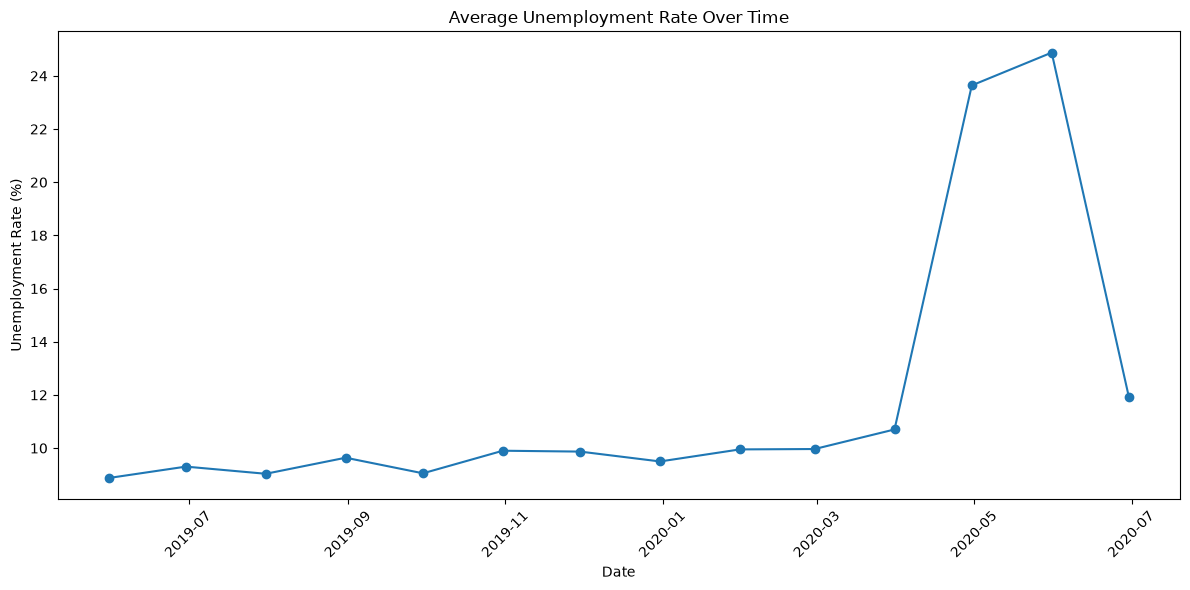

In [8]:
plt.figure(figsize=(12, 6))

monthly_unemployment = (
    df.groupby("Date")["Estimated Unemployment Rate (%)"]
    .mean()
)

plt.plot(
    monthly_unemployment.index,
    monthly_unemployment.values,
    marker="o"
)

plt.title("Average Unemployment Rate Over Time")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. Unemployment Rate by Area

This analysis compares the average unemployment rate between rural and
urban areas.

Area
Urban    13.166614
Rural    10.324791
Name: Estimated Unemployment Rate (%), dtype: float64


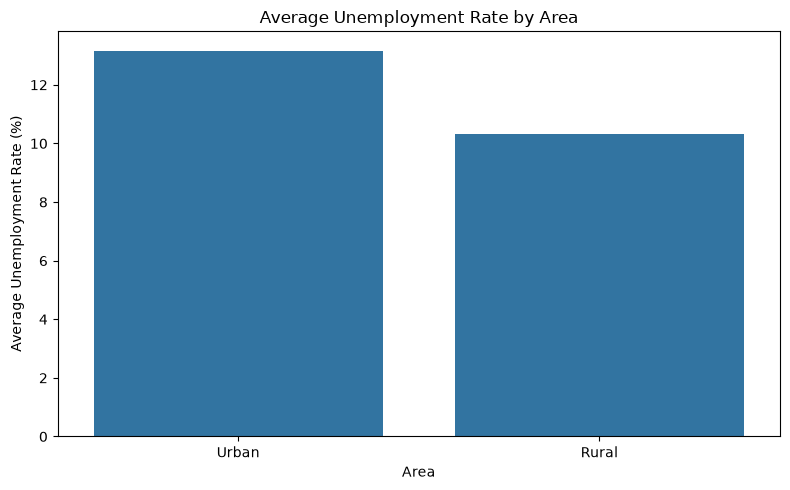

In [9]:
area_unemployment = (
    df.groupby("Area")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

print(area_unemployment)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=area_unemployment.index,
    y=area_unemployment.values
)

plt.title("Average Unemployment Rate by Area")
plt.xlabel("Area")
plt.ylabel("Average Unemployment Rate (%)")

plt.tight_layout()
plt.show()

## 8. Unemployment Rate by Region

This analysis compares the average unemployment rate across the regions
included in the dataset.

Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Punjab              12.031071
Puducherry          10.215000
Kerala              10.123929
Tamil Nadu           9.284286
Goa                  9.274167
Chhattisgarh         9.240357
West Bengal          8.124643
Telangana            7.737857
Maharashtra          7.557500
Andhra Pradesh       7.477143
Madhya Pradesh       7.406429
Sikkim               7.249412
Karnataka            6.676071
Gujarat              6.663929
Uttarakhand          6.582963
Assam                6.428077
Odisha               5.657857
Meghalaya            4.798889
Name: Estimated Unemployment Rate (%), dtype: float64


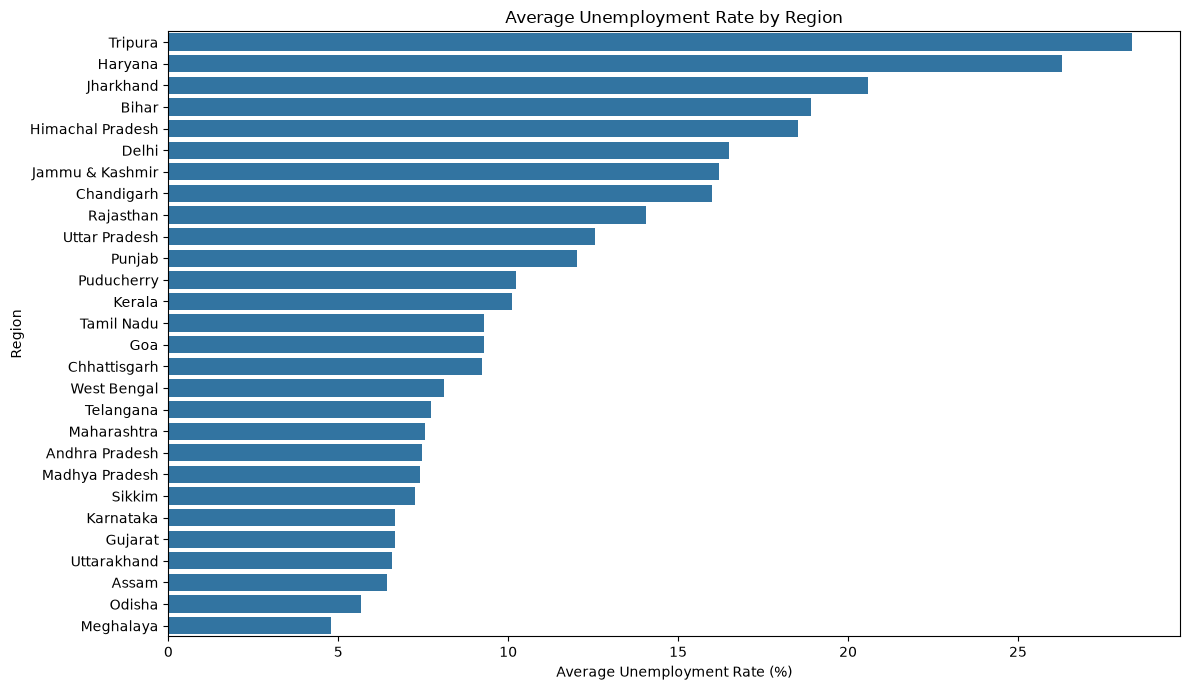

In [10]:
region_unemployment = (
    df.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

print(region_unemployment)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=region_unemployment.values,
    y=region_unemployment.index
)

plt.title("Average Unemployment Rate by Region")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")

plt.tight_layout()
plt.show()

## 9. COVID-19 Impact on Unemployment

The dataset includes observations from 2019 to 2020. The unemployment rate
during the early COVID-19 period is compared with the preceding period to
observe changes in unemployment.

In [11]:
covid_data = df[
    (df["Date"] >= "2020-03-01") &
    (df["Date"] <= "2020-06-30")
]

pre_covid_data = df[
    (df["Date"] < "2020-03-01")
]

pre_covid_rate = pre_covid_data["Estimated Unemployment Rate (%)"].mean()
covid_rate = covid_data["Estimated Unemployment Rate (%)"].mean()

print(f"Average unemployment rate before March 2020: {pre_covid_rate:.2f}%")
print(f"Average unemployment rate from March to June 2020: {covid_rate:.2f}%")

Average unemployment rate before March 2020: 9.51%
Average unemployment rate from March to June 2020: 17.77%


## 10. COVID-19 Period Comparison

The average unemployment rate before March 2020 is compared with the
average rate from March to June 2020.

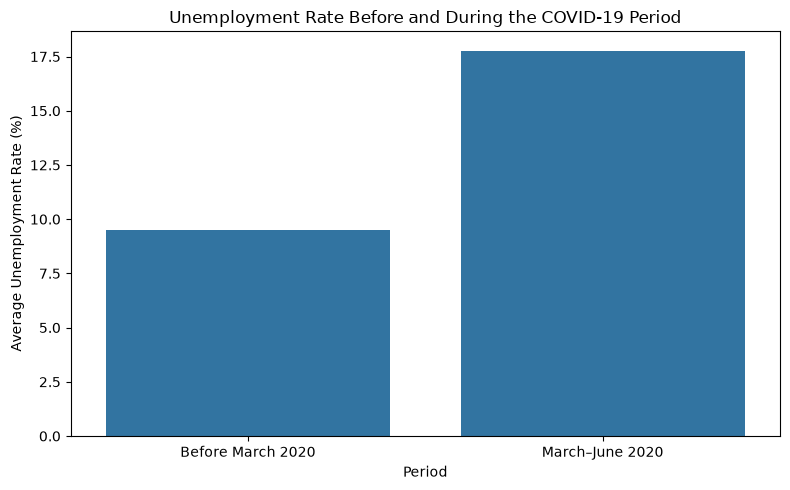

In [12]:
comparison = pd.Series(
    {
        "Before March 2020": pre_covid_rate,
        "March–June 2020": covid_rate
    }
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=comparison.index,
    y=comparison.values
)

plt.title("Unemployment Rate Before and During the COVID-19 Period")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")

plt.tight_layout()
plt.show()

## 11. Monthly Unemployment Rate Pattern

The monthly average unemployment rate is examined to identify changes and
patterns over time.

In [13]:
monthly_data = (
    df.groupby("Date")["Estimated Unemployment Rate (%)"]
    .mean()
    .reset_index()
)

monthly_data["Month"] = monthly_data["Date"].dt.strftime("%b %Y")

print(monthly_data)

         Date  Estimated Unemployment Rate (%)     Month
0  2019-05-31                         8.874259  May 2019
1  2019-06-30                         9.303333  Jun 2019
2  2019-07-31                         9.033889  Jul 2019
3  2019-08-31                         9.637925  Aug 2019
4  2019-09-30                         9.051731  Sep 2019
5  2019-10-31                         9.900909  Oct 2019
6  2019-11-30                         9.868364  Nov 2019
7  2019-12-31                         9.497358  Dec 2019
8  2020-01-31                         9.950755  Jan 2020
9  2020-02-29                         9.964717  Feb 2020
10 2020-03-31                        10.700577  Mar 2020
11 2020-04-30                        23.641569  Apr 2020
12 2020-05-31                        24.875294  May 2020
13 2020-06-30                        11.903600  Jun 2020


## 12. Monthly Unemployment Trend

The monthly average unemployment rate is visualized to highlight changes
throughout the period covered by the dataset.

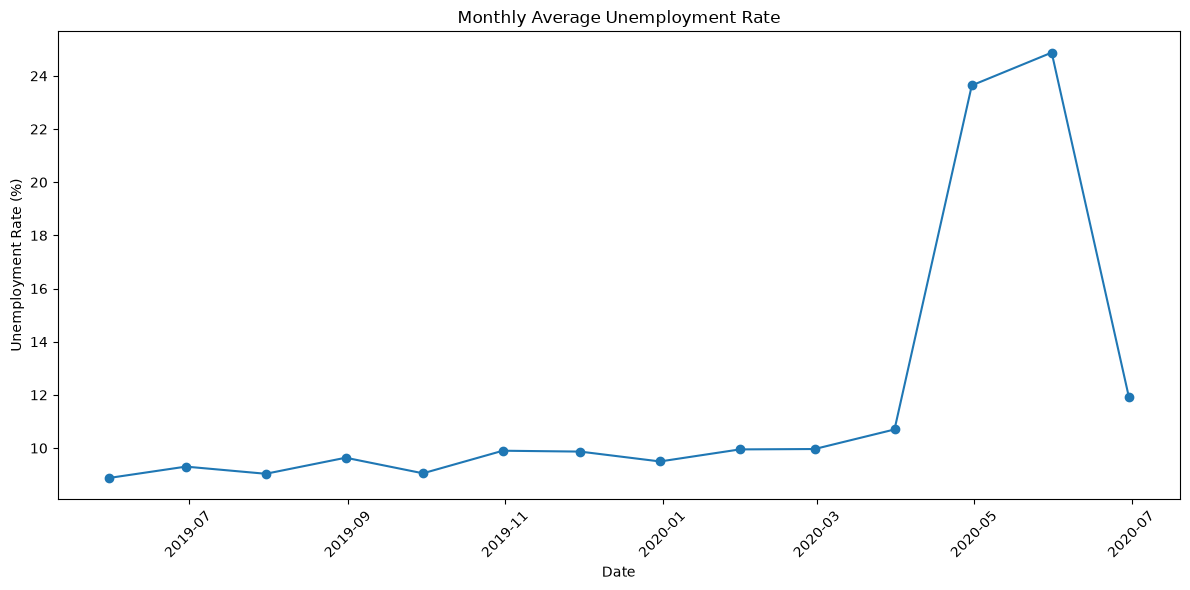

In [14]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_data["Date"],
    monthly_data["Estimated Unemployment Rate (%)"],
    marker="o"
)

plt.title("Monthly Average Unemployment Rate")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 13. Key Findings

The analysis produced the following findings:

- The dataset contains 740 complete observations after removing missing values.
- The average unemployment rate was relatively stable during 2019 and the
  first two months of 2020.
- The average unemployment rate increased sharply from 10.70% in March 2020
  to 23.64% in April 2020.
- The highest monthly average unemployment rate in the dataset was 24.88%
  in May 2020.
- The rate decreased to 11.90% in June 2020.
- The average unemployment rate before March 2020 was 9.51%, compared with
  17.77% during March–June 2020.
- Urban observations had an average unemployment rate of 13.17%, compared
  with 10.32% for rural observations.
- Unemployment rates varied substantially across the regions represented
  in the dataset.

These findings describe patterns observed in the dataset and do not by
themselves establish causal relationships.

## 14. Conclusion

This analysis explored unemployment trends, regional differences, rural and
urban differences, and changes during the March–June 2020 period. The
visualizations show a pronounced increase in unemployment during the
COVID-19 period represented in the dataset.

## 15. Save Analysis Results

The main analysis results are saved as CSV files for reference and
documentation.

In [15]:
# Save monthly unemployment trend
monthly_data.to_csv(
    "../results/monthly_unemployment.csv",
    index=False
)

# Save unemployment rate by area
area_unemployment.to_csv(
    "../results/unemployment_by_area.csv"
)

# Save unemployment rate by region
region_unemployment.to_csv(
    "../results/unemployment_by_region.csv"
)

# Save COVID-19 comparison
covid_comparison = pd.DataFrame({
    "Period": [
        "Before March 2020",
        "March-June 2020"
    ],
    "Average Unemployment Rate (%)": [
        pre_covid_rate,
        covid_rate
    ]
})

covid_comparison.to_csv(
    "../results/covid_comparison.csv",
    index=False
)

print("Analysis results saved successfully.")

Analysis results saved successfully.
